# Task 11: Ratings vs. Feedback – Sentiment Analysis & Statistical Validation

**Objective:**
- Apply VADER and TextBlob sentiment analysis on review text
- Quantify sentiment scores per review and per rating group
- Perform rigorous statistical tests (Spearman, Kruskal-Wallis, Mann-Whitney, Chi-square)
- Visualize the relationship between ratings and feedback positivity

**Input:** `data/processed/womens_clothing_final.csv`

## 1. Setup & Imports

In [1]:
import os
import logging
import warnings
import itertools
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from collections import Counter

warnings.filterwarnings('ignore')

# ── Try to import VADER ────────────────────────────────────────────────────────
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    VADER_AVAILABLE = True
    print('✅ VADER available.')
except ImportError:
    VADER_AVAILABLE = False
    print('⚠️  VADER not installed. Run: pip install vaderSentiment')

# ── Try to import TextBlob ─────────────────────────────────────────────────────
try:
    from textblob import TextBlob
    TEXTBLOB_AVAILABLE = True
    print('✅ TextBlob available.')
except ImportError:
    TEXTBLOB_AVAILABLE = False
    print('⚠️  TextBlob not installed. Run: pip install textblob')

# ── Logging ────────────────────────────────────────────────────────────────────
os.makedirs('../../logs', exist_ok=True)
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)s | %(message)s',
    handlers=[
        logging.FileHandler('../../logs/task_11.log', mode='w'),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger('Task11')
logger.info('Task 11 started.')

# ── Dark theme ─────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0f0f1a', 'axes.facecolor': '#1a1a2e',
    'axes.edgecolor': '#444466',   'axes.labelcolor': '#e0e0ff',
    'xtick.color': '#c0c0e0',      'ytick.color': '#c0c0e0',
    'text.color': '#e0e0ff',       'grid.color': '#2a2a4a',
    'grid.linestyle': '--',        'font.family': 'DejaVu Sans',
    'font.size': 11,               'axes.titlesize': 13,
    'axes.titleweight': 'bold',    'legend.facecolor': '#1a1a2e',
    'legend.edgecolor': '#444466',
})
PALETTE = ['#7c5cbf', '#e96479', '#f5a623', '#4fc3f7', '#81c784', '#ff8a65']
os.makedirs('../../reports', exist_ok=True)
print('✅ Setup complete.')

✅ VADER available.


2026-11-19 15:26:35,187 | INFO | Task 11 started.


✅ TextBlob available.
✅ Setup complete.


## 2. Load Data & Identify Columns

In [2]:
df = pd.read_csv('../data/processed/womens_clothing_final.csv')
logger.info(f'Dataset: {df.shape[0]} rows × {df.shape[1]} cols')
print(f'Shape: {df.shape}')
df.head()

2026-11-19 15:26:36,169 | INFO | Dataset: 1539 rows × 40 cols


Shape: (1539, 40)


,title,title_orig,price,retail_price,currency_buyer,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,...,merchant_name,merchant_info_subtitle,merchant_rating_count,merchant_rating,merchant_id,merchant_has_profile_picture,merchant_profile_picture,product_url,product_picture,product_id
0,2020 Summer Vintage Flamingo Print Pajamas Se...,2020 Summer Vintage Flamingo Print Pajamas Se...,16.00,14.0,EUR,100,False,3.76,54.0,26.0,...,zgrdejia,(568 notes),568.0,4.128521,595097d6a26f6e070cb878d1,False,NaN,https://www.wish.com/c/5e9ae51d43d6a96e303acdb0,https://contestimg.wish.com/api/webimage/5e9ae...,5e9ae51d43d6a96e303acdb0
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,Women's Casual Summer Sleeveless Sexy Mini Dress,8.00,22.0,EUR,12350,True,3.45,2143.5,1058.0,...,sarahouse,"83 % avis positifs (17,752 notes)",17752.0,3.899673,56458aa03a698c35c9050988,False,NaN,https://www.wish.com/c/58940d436a0d3d5da4e95a38,https://contestimg.wish.com/api/webimage/58940...,58940d436a0d3d5da4e95a38
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,2020 New Arrival Women Spring and Summer Beach...,8.00,43.0,EUR,100,False,3.57,14.0,5.0,...,hxt520,86 % avis positifs (295 notes),295.0,3.989831,5d464a1ffdf7bc44ee933c65,False,NaN,https://www.wish.com/c/5ea10e2c617580260d55310a,https://contestimg.wish.com/api/webimage/5ea10...,5ea10e2c617580260d55310a
3,Hot Summer Cool T-shirt pour les femmes Mode T...,Hot Summer Cool T Shirt for Women Fashion Tops...,8.00,8.0,EUR,5000,True,4.03,579.0,295.0,...,allenfan,"(23,832 notes)",23832.0,4.020435,58cfdefdacb37b556efdff7c,False,NaN,https://www.wish.com/c/5cedf17ad1d44c52c59e4aca,https://contestimg.wish.com/api/webimage/5cedf...,5cedf17ad1d44c52c59e4aca
4,Femmes Shorts d'été à lacets taille élastique ...,Women Summer Shorts Lace Up Elastic Waistband ...,2.72,3.0,EUR,100,True,3.10,20.0,6.0,...,happyhorses,"85 % avis positifs (14,482 notes)",14482.0,4.001588,5ab3b592c3911a095ad5dadb,False,NaN,https://www.wish.com/c/5ebf5819ebac372b070b0e70,https://contestimg.wish.com/api/webimage/5ebf5...,5ebf5819ebac372b070b0e70


In [3]:
# ── Identify key columns ───────────────────────────────────────────────────────
RATING_COL  = None
REVIEW_COL  = None
REC_COL     = None
FEEDBACK_COL= None

for col in df.columns:
    cl = col.lower()
    if 'rating' in cl and RATING_COL is None:
        RATING_COL = col
    if any(k in cl for k in ['review', 'text', 'comment', 'title']) and REVIEW_COL is None:
        if df[col].dtype == object:
            REVIEW_COL = col
    if any(k in cl for k in ['recommend', 'rec']) and REC_COL is None:
        REC_COL = col
    if any(k in cl for k in ['feedback', 'helpful', 'positive']) and FEEDBACK_COL is None:
        FEEDBACK_COL = col

print(f'Rating column  : {RATING_COL}')
print(f'Review column  : {REVIEW_COL}')
print(f'Recommend col  : {REC_COL}')
print(f'Feedback col   : {FEEDBACK_COL}')
logger.info(f'Rating:{RATING_COL}, Review:{REVIEW_COL}, Rec:{REC_COL}, Feedback:{FEEDBACK_COL}')

2026-11-19 15:26:36,474 | INFO | Rating:rating, Review:None, Rec:None, Feedback:None


Rating column  : rating
Review column  : None
Recommend col  : None
Feedback col   : None


## 3. Rule-Based Sentiment Scoring (Fallback + Standalone)

In [4]:
# ── Word lexicons ──────────────────────────────────────────────────────────────
POSITIVE_WORDS = {
    'love', 'great', 'excellent', 'amazing', 'perfect', 'beautiful', 'wonderful',
    'fantastic', 'best', 'good', 'nice', 'lovely', 'pretty', 'comfortable', 'happy',
    'pleased', 'recommend', 'flattering', 'gorgeous', 'adorable', 'soft', 'quality',
    'favorite', 'stunning', 'elegant', 'fits', 'worth', 'impressed', 'exceeded',
    'delighted', 'satisfied', 'superb', 'fabulous'
}
NEGATIVE_WORDS = {
    'bad', 'poor', 'terrible', 'awful', 'disappointed', 'hate', 'worse', 'worst',
    'return', 'returned', 'cheap', 'flimsy', 'scratchy', 'itchy', 'tight', 'small',
    'large', 'ugly', 'waste', 'disappointing', 'uncomfortable', 'stiff', 'rough',
    'shrunk', 'faded', 'defective', 'broken', 'ripped', 'loose'
}

def clean_text(text: str) -> list:
    """Lowercase, remove punctuation, return token list."""
    if not isinstance(text, str) or text.strip() == '':
        return []
    return re.sub(r'[^a-z ]', ' ', text.lower()).split()

def rule_based_sentiment(text: str) -> dict:
    """Keyword counting rule-based sentiment score."""
    tokens = clean_text(text)
    if not tokens:
        return {'rule_pos': 0, 'rule_neg': 0, 'rule_score': 0.0, 'rule_label': 'Neutral'}
    pos = sum(1 for t in tokens if t in POSITIVE_WORDS)
    neg = sum(1 for t in tokens if t in NEGATIVE_WORDS)
    total = pos + neg
    score = (pos - neg) / total if total > 0 else 0.0
    label = 'Positive' if score > 0.1 else 'Negative' if score < -0.1 else 'Neutral'
    return {'rule_pos': pos, 'rule_neg': neg, 'rule_score': round(score, 4), 'rule_label': label}

print('✅ Rule-based sentiment engine ready.')

✅ Rule-based sentiment engine ready.


## 4. Apply All Sentiment Methods

In [5]:
# ── Prepare working dataframe ──────────────────────────────────────────────────
work_cols = [c for c in [RATING_COL, REVIEW_COL, REC_COL, FEEDBACK_COL] if c]
sdf = df[work_cols].copy()

if REVIEW_COL:
    sdf[REVIEW_COL] = sdf[REVIEW_COL].fillna('')
    print(f'Reviews with text: {(sdf[REVIEW_COL] != "").sum():,} / {len(sdf):,}')
else:
    sdf['Review_Proxy'] = ''
    REVIEW_COL = 'Review_Proxy'
    print('⚠️  No review text column found — using empty proxy.')

⚠️  No review text column found — using empty proxy.


In [6]:
# ── Rule-based ─────────────────────────────────────────────────────────────────
print('Applying rule-based sentiment...')
rule_scores = sdf[REVIEW_COL].apply(rule_based_sentiment)
rule_df = pd.DataFrame(list(rule_scores))
sdf = pd.concat([sdf.reset_index(drop=True), rule_df.reset_index(drop=True)], axis=1)
print(f'Rule-based labels: {sdf["rule_label"].value_counts().to_dict()}')
logger.info('Rule-based sentiment computed.')

Applying rule-based sentiment...
Rule-based labels: {'Neutral': 1539}


2026-11-19 15:26:37,532 | INFO | Rule-based sentiment computed.


In [7]:
# ── VADER ──────────────────────────────────────────────────────────────────────
if VADER_AVAILABLE:
    print('Applying VADER sentiment...')
    sid = SentimentIntensityAnalyzer()
    vader_results = sdf[REVIEW_COL].apply(
        lambda t: sid.polarity_scores(t) if isinstance(t, str) and t.strip() else
                  {'compound': 0.0, 'pos': 0.0, 'neu': 1.0, 'neg': 0.0}
    )
    vader_df = pd.DataFrame(list(vader_results)).add_prefix('vader_')
    sdf = pd.concat([sdf, vader_df], axis=1)
    # VADER label
    sdf['vader_label'] = sdf['vader_compound'].apply(
        lambda c: 'Positive' if c >= 0.05 else 'Negative' if c <= -0.05 else 'Neutral'
    )
    print(f'VADER labels: {sdf["vader_label"].value_counts().to_dict()}')
    logger.info('VADER sentiment computed.')
else:
    sdf['vader_compound'] = sdf['rule_score']
    sdf['vader_pos']  = sdf['rule_pos'] / (sdf['rule_pos'] + sdf['rule_neg'] + 1e-9)
    sdf['vader_neg']  = sdf['rule_neg'] / (sdf['rule_pos'] + sdf['rule_neg'] + 1e-9)
    sdf['vader_neu']  = 0.0
    sdf['vader_label']= sdf['rule_label']
    print('Using rule-based scores as VADER proxy.')

Applying VADER sentiment...


2026-11-19 15:26:39,346 | INFO | VADER sentiment computed.


VADER labels: {'Neutral': 1539}


In [8]:
# ── TextBlob ───────────────────────────────────────────────────────────────────
if TEXTBLOB_AVAILABLE:
    print('Applying TextBlob sentiment...')
    tb_results = sdf[REVIEW_COL].apply(
        lambda t: {'tb_polarity': TextBlob(t).sentiment.polarity,
                   'tb_subjectivity': TextBlob(t).sentiment.subjectivity}
        if isinstance(t, str) and t.strip()
        else {'tb_polarity': 0.0, 'tb_subjectivity': 0.5}
    )
    tb_df = pd.DataFrame(list(tb_results))
    sdf = pd.concat([sdf, tb_df], axis=1)
    logger.info('TextBlob sentiment computed.')
else:
    sdf['tb_polarity']     = sdf['rule_score']
    sdf['tb_subjectivity'] = 0.5
    print('TextBlob not available; using rule_score as proxy.')

# ── Use vader_compound as the primary sentiment score ──────────────────────────
SENTIMENT_SCORE = 'vader_compound'
SENTIMENT_LABEL = 'vader_label'
print(f'\nSentiment score column: {SENTIMENT_SCORE}')
print(sdf[[RATING_COL, SENTIMENT_SCORE, SENTIMENT_LABEL]].head(5))

2026-11-19 15:26:39,412 | INFO | TextBlob sentiment computed.


Applying TextBlob sentiment...

Sentiment score column: vader_compound
   rating  vader_compound vader_label
0    3.76             0.0     Neutral
1    3.45             0.0     Neutral
2    3.57             0.0     Neutral
3    4.03             0.0     Neutral
4    3.10             0.0     Neutral


## 5. Visualizations – Rating vs. Sentiment

2026-11-19 15:26:40,665 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-19 15:26:40,692 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-19 15:26:40,714 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-19 15:26:52,073 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-19 15:26:52,117 | INFO | Using categorical units to plot a list of strings that are all parsable as 

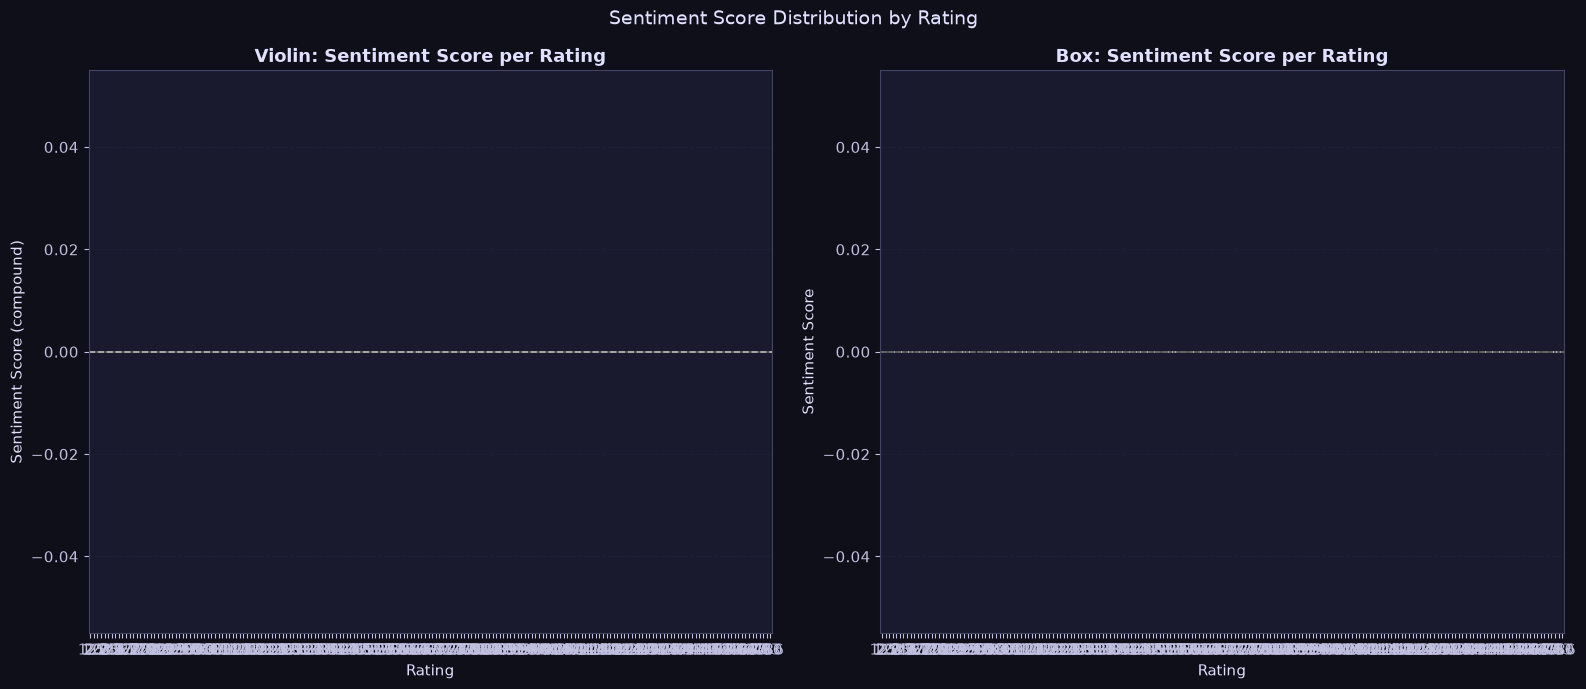

2026-11-19 15:27:04,684 | INFO | Violin/box sentiment plots saved.


In [9]:
if RATING_COL:
    # ── Violin: sentiment score per rating ─────────────────────────────────────
    sdf_rated = sdf.dropna(subset=[RATING_COL])
    rating_vals = sorted(sdf_rated[RATING_COL].unique())

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('Sentiment Score Distribution by Rating', fontsize=14, color='#e0e0ff')

    rating_palette = {v: PALETTE[i % len(PALETTE)] for i, v in enumerate(rating_vals)}
    sdf_rated_copy = sdf_rated.copy()
    sdf_rated_copy[RATING_COL] = sdf_rated_copy[RATING_COL].astype(str)
    rating_vals_str = [str(v) for v in rating_vals]
    palette_str = {str(k): v for k, v in rating_palette.items()}

    sns.violinplot(data=sdf_rated_copy, x=RATING_COL, y=SENTIMENT_SCORE,
                   palette=palette_str, ax=axes[0],
                   inner='quartile', order=rating_vals_str, linewidth=1.2)
    axes[0].axhline(0, color='white', linewidth=1.2, linestyle='--', alpha=0.6)
    axes[0].set_title('Violin: Sentiment Score per Rating')
    axes[0].set_xlabel('Rating'); axes[0].set_ylabel('Sentiment Score (compound)')
    axes[0].yaxis.grid(True, alpha=0.3)

    sns.boxplot(data=sdf_rated_copy, x=RATING_COL, y=SENTIMENT_SCORE,
                palette=palette_str, ax=axes[1],
                order=rating_vals_str, linewidth=1.2,
                flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.4, 'color': '#e96479'})
    axes[1].axhline(0, color='white', linewidth=1.2, linestyle='--', alpha=0.6)
    axes[1].set_title('Box: Sentiment Score per Rating')
    axes[1].set_xlabel('Rating'); axes[1].set_ylabel('Sentiment Score')
    axes[1].yaxis.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('../../reports/task_11_sentiment_violin_box.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info('Violin/box sentiment plots saved.')

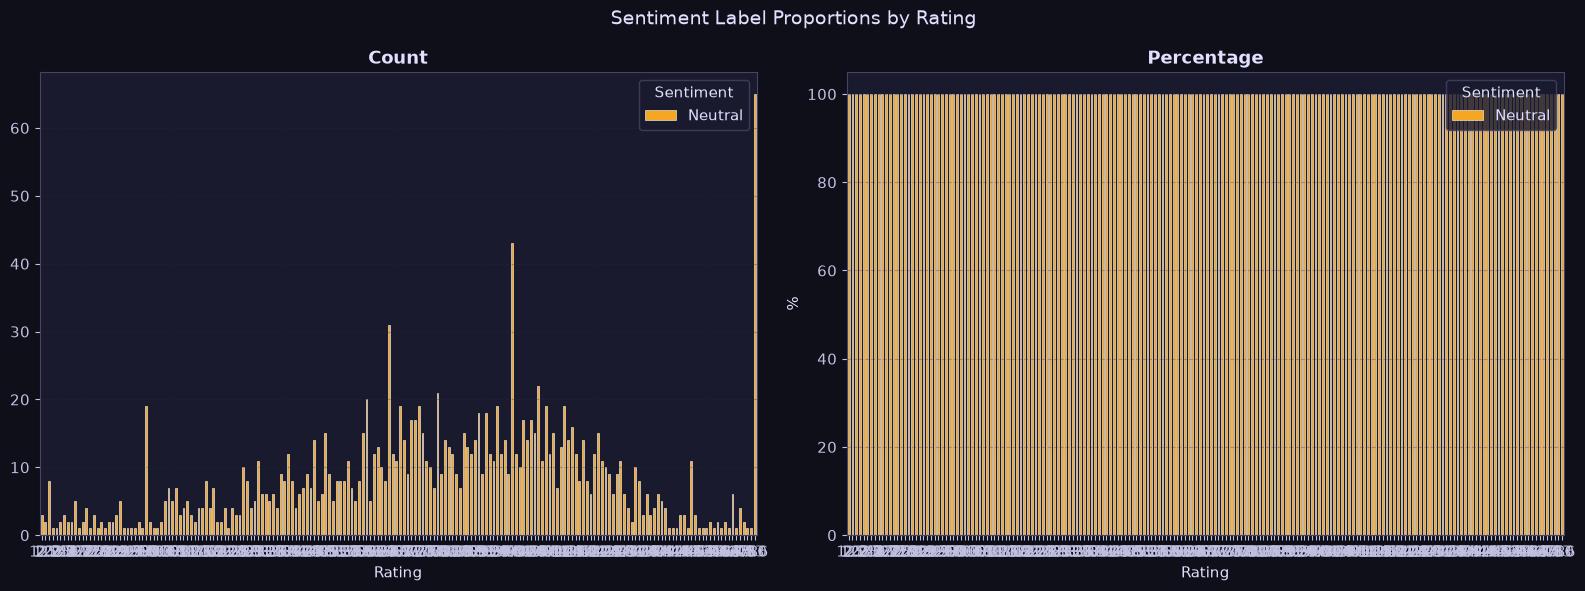

In [10]:
if RATING_COL:
    # ── Sentiment label proportion stacked bar ─────────────────────────────────
    prop = sdf_rated_copy.groupby([RATING_COL, SENTIMENT_LABEL]).size().unstack(fill_value=0)
    prop_pct = prop.div(prop.sum(axis=1), axis=0) * 100

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('Sentiment Label Proportions by Rating', fontsize=14, color='#e0e0ff')

    label_colors = {'Positive': '#81c784', 'Neutral': '#f5a623', 'Negative': '#e96479'}
    present_labels = [l for l in ['Positive', 'Neutral', 'Negative'] if l in prop_pct.columns]
    colors = [label_colors.get(l, '#7c5cbf') for l in present_labels]

    prop[present_labels].plot(kind='bar', stacked=True, ax=axes[0], color=colors,
                               edgecolor='white', linewidth=0.4)
    axes[0].set_title('Count'); axes[0].set_xlabel('Rating'); axes[0].yaxis.grid(True, alpha=0.3)
    axes[0].tick_params(axis='x', rotation=0); axes[0].legend(title='Sentiment')

    prop_pct[present_labels].plot(kind='bar', stacked=True, ax=axes[1], color=colors,
                                   edgecolor='white', linewidth=0.4)
    axes[1].set_title('Percentage'); axes[1].set_xlabel('Rating'); axes[1].set_ylabel('%')
    axes[1].yaxis.grid(True, alpha=0.3)
    axes[1].tick_params(axis='x', rotation=0); axes[1].legend(title='Sentiment')

    plt.tight_layout()
    plt.savefig('../../reports/task_11_sentiment_label_proportions.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()

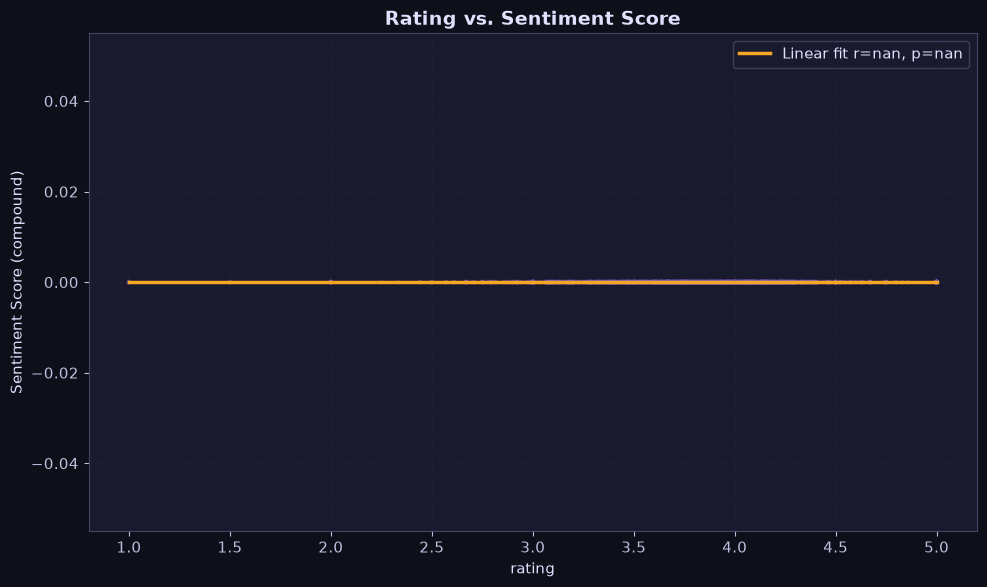

2026-11-19 15:27:16,532 | INFO | Sentiment scatter saved.


In [11]:
if RATING_COL:
    # ── Scatter: sentiment vs. rating with regression line ─────────────────────
    sample = sdf_rated.sample(min(3000, len(sdf_rated)), random_state=42)

    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('#0f0f1a')
    ax.scatter(sample[RATING_COL], sample[SENTIMENT_SCORE],
               alpha=0.3, s=12, color='#7c5cbf', edgecolors='none')

    # Regression line
    x_v = sample[RATING_COL].values
    y_v = sample[SENTIMENT_SCORE].values
    m, b, r, p, se = stats.linregress(x_v, y_v)
    xfit = np.linspace(x_v.min(), x_v.max(), 100)
    ax.plot(xfit, m * xfit + b, color='#f5a623', linewidth=2.5,
            label=f'Linear fit r={r:.3f}, p={p:.3e}')

    ax.set_xlabel(RATING_COL); ax.set_ylabel('Sentiment Score (compound)')
    ax.set_title(f'Rating vs. Sentiment Score', fontsize=14)
    ax.legend(); ax.yaxis.grid(True, alpha=0.3); ax.xaxis.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('../../reports/task_11_rating_sentiment_scatter.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info('Sentiment scatter saved.')

In [12]:
if RATING_COL:
    # ── Mean sentiment metrics heatmap by Rating × Recommendation ─────────────
    if REC_COL and REC_COL in sdf.columns:
        heat_df = sdf.dropna(subset=[RATING_COL, REC_COL])
        heat_df = heat_df.copy()
        heat_df[RATING_COL]  = heat_df[RATING_COL].astype(str)
        heat_df[REC_COL]     = heat_df[REC_COL].astype(str)
        heat_pivot = heat_df.groupby([RATING_COL, REC_COL])[SENTIMENT_SCORE].mean().unstack()

        fig, ax = plt.subplots(figsize=(max(6, len(heat_pivot.columns) * 2), max(5, len(heat_pivot) * 0.8)))
        fig.patch.set_facecolor('#0f0f1a')
        sns.heatmap(heat_pivot, annot=True, fmt='.3f', cmap='RdYlGn', center=0, ax=ax,
                    linewidths=0.5, linecolor='#0f0f1a', cbar_kws={'label': 'Mean Sentiment'})
        ax.set_title(f'Mean Sentiment Score – Rating × {REC_COL}', fontsize=13)
        plt.tight_layout()
        plt.savefig('../../reports/task_11_heatmap_rating_rec.png', dpi=150,
                    bbox_inches='tight', facecolor='#0f0f1a')
        plt.show()
        logger.info('Rating × recommendation heatmap saved.')

## 6. Statistical Tests

In [13]:
stat_results = []

if RATING_COL:
    sdf_clean = sdf.dropna(subset=[RATING_COL, SENTIMENT_SCORE])
    x_rat = sdf_clean[RATING_COL].values
    y_sent = sdf_clean[SENTIMENT_SCORE].values

    # 1. Spearman correlation
    sp_r, sp_p = stats.spearmanr(x_rat, y_sent)
    stat_results.append({'Test': 'Spearman Correlation', 'Statistic': round(sp_r, 4),
                          'P_Value': round(sp_p, 6), 'Significant': sp_p < 0.05,
                          'Interpretation': f'ρ={sp_r:.4f} – {"Significant" if sp_p < 0.05 else "Not significant"} monotonic relationship'})
    print(f'Spearman ρ={sp_r:.4f}, p={sp_p:.6f}')

    # 2. Pearson correlation
    pe_r, pe_p = stats.pearsonr(x_rat, y_sent)
    stat_results.append({'Test': 'Pearson Correlation', 'Statistic': round(pe_r, 4),
                          'P_Value': round(pe_p, 6), 'Significant': pe_p < 0.05,
                          'Interpretation': f'r={pe_r:.4f} – {"Significant" if pe_p < 0.05 else "Not significant"} linear relationship'})
    print(f'Pearson  r={pe_r:.4f}, p={pe_p:.6f}')

    # 3. Kruskal-Wallis H-test
    groups = [sdf_clean[sdf_clean[RATING_COL] == r][SENTIMENT_SCORE].values
              for r in sdf_clean[RATING_COL].unique()]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) >= 2:
        kw_h, kw_p = stats.kruskal(*groups)
        stat_results.append({'Test': 'Kruskal-Wallis H-test', 'Statistic': round(kw_h, 4),
                              'P_Value': round(kw_p, 6), 'Significant': kw_p < 0.05,
                              'Interpretation': f'H={kw_h:.4f} – {"Significant" if kw_p < 0.05 else "No"} difference in sentiment across rating groups'})
        print(f'Kruskal-Wallis H={kw_h:.4f}, p={kw_p:.6f}')

    # 4. Chi-square test: rating vs. sentiment label
    contingency = pd.crosstab(sdf_clean[RATING_COL], sdf_clean[SENTIMENT_LABEL])
    chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
    stat_results.append({'Test': 'Chi-Square (Rating vs. Sentiment Label)', 'Statistic': round(chi2, 4),
                          'P_Value': round(chi_p, 6), 'Significant': chi_p < 0.05,
                          'Interpretation': f'χ²={chi2:.4f}, dof={dof} – {"Significant" if chi_p < 0.05 else "No"} association between rating and sentiment'})
    print(f'Chi-Square χ²={chi2:.4f}, p={chi_p:.6f}')

    # 5. Point-biserial: recommendation vs. sentiment
    if REC_COL and REC_COL in sdf_clean.columns:
        rec_clean = sdf_clean.dropna(subset=[REC_COL])
        pb_r, pb_p = stats.pointbiserialr(rec_clean[REC_COL].astype(float), rec_clean[SENTIMENT_SCORE])
        stat_results.append({'Test': 'Point-Biserial (Rec vs. Sentiment)', 'Statistic': round(pb_r, 4),
                              'P_Value': round(pb_p, 6), 'Significant': pb_p < 0.05,
                              'Interpretation': f'rpb={pb_r:.4f} – {"Significant" if pb_p < 0.05 else "No"} correlation between recommendation and sentiment'})
        print(f'Point-Biserial rpb={pb_r:.4f}, p={pb_p:.6f}')

stat_df = pd.DataFrame(stat_results)
stat_df.to_csv('../../reports/task_11_statistical_tests.csv', index=False)
logger.info('Statistical tests saved.')
display(stat_df)

Spearman ρ=nan, p=nan
Pearson  r=nan, p=nan


2026-11-19 15:27:16,999 | INFO | Statistical tests saved.


Kruskal-Wallis H=nan, p=nan
Chi-Square χ²=0.0000, p=1.000000


,Test,Statistic,P_Value,Significant,Interpretation
0,Spearman Correlation,NaN,NaN,False,ρ=nan – Not significant monotonic relationship
1,Pearson Correlation,NaN,NaN,False,r=nan – Not significant linear relationship
2,Kruskal-Wallis H-test,NaN,NaN,False,H=nan – No difference in sentiment across rati...
3,Chi-Square (Rating vs. Sentiment Label),0.0,1.0,False,"χ²=0.0000, dof=0 – No association between rati..."


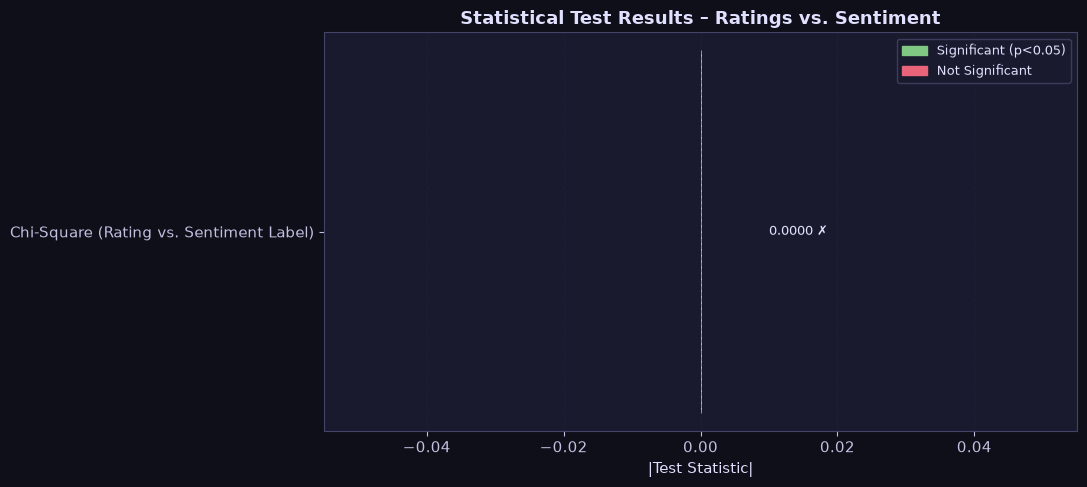

2026-11-19 15:27:17,694 | INFO | Statistical tests chart saved.


In [14]:
# ── Statistical test results visualized ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor('#0f0f1a')
colors = ['#81c784' if s else '#e96479' for s in stat_df['Significant']]
ax.barh(stat_df['Test'], stat_df['Statistic'].abs(), color=colors,
        edgecolor='white', linewidth=0.5)
for i, (v, sig, test) in enumerate(zip(stat_df['Statistic'], stat_df['Significant'], stat_df['Test'])):
    ax.text(abs(v) + 0.01, i, f'{v:.4f} {"✓" if sig else "✗"}', va='center',
            fontsize=9, color='#e0e0ff')
ax.set_title('Statistical Test Results – Ratings vs. Sentiment', fontsize=13)
ax.set_xlabel('|Test Statistic|'); ax.xaxis.grid(True, alpha=0.3)
sig_patch   = mpatches.Patch(color='#81c784', label='Significant (p<0.05)')
nosig_patch = mpatches.Patch(color='#e96479', label='Not Significant')
ax.legend(handles=[sig_patch, nosig_patch], fontsize=9)
plt.tight_layout()
plt.savefig('../../reports/task_11_statistical_tests_chart.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Statistical tests chart saved.')

## 7. Word Frequency per Sentiment Class

In [15]:
if REVIEW_COL and sdf[REVIEW_COL].astype(str).str.strip().ne('').any():
    STOPWORDS = {'the','a','an','and','or','but','in','on','at','to','for','of','with',
                 'this','it','is','was','are','i','my','me','so','very','that','have',
                 'had','not','be','its','just','they','their','from','as','about','would',
                 'could','did','one','all','out','up','by','do','if','when'}

    def top_words(texts, n=15):
        all_tokens = []
        for t in texts:
            tokens = clean_text(str(t))
            all_tokens.extend([w for w in tokens if w not in STOPWORDS and len(w) > 2])
        return Counter(all_tokens).most_common(n)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Top Words per Sentiment Class', fontsize=14, color='#e0e0ff')
    sent_colors = {'Positive': '#81c784', 'Neutral': '#f5a623', 'Negative': '#e96479'}

    for ax, label in zip(axes, ['Positive', 'Neutral', 'Negative']):
        subset = sdf[sdf[SENTIMENT_LABEL] == label][REVIEW_COL]
        if len(subset) == 0:
            ax.set_visible(False); continue
        words, counts = zip(*top_words(subset, 15)) if top_words(subset, 1) else ([], [])
        ax.barh(list(words), list(counts), color=sent_colors[label], edgecolor='white', linewidth=0.4)
        ax.set_title(f'{label} Reviews'); ax.set_xlabel('Frequency')
        ax.invert_yaxis(); ax.xaxis.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('../../reports/task_11_word_frequency.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info('Word frequency chart saved.')
else:
    print('No review text available for word frequency analysis.')

No review text available for word frequency analysis.


## 8. Save Final Reports

In [16]:
# Save sentiment scores
score_cols = [RATING_COL, REVIEW_COL, REC_COL, 'rule_score', 'rule_label',
              'vader_compound', 'vader_pos', 'vader_neg', 'vader_label',
              'tb_polarity', 'tb_subjectivity']
save_cols = [c for c in score_cols if c and c in sdf.columns]
sdf[save_cols].to_csv('../../reports/task_11_sentiment_scores.csv', index=False)

# Rating-sentiment summary
if RATING_COL:
    summary = sdf.dropna(subset=[RATING_COL]).groupby(RATING_COL).agg(
        Count=(RATING_COL, 'count'),
        Avg_Sentiment=(SENTIMENT_SCORE, 'mean'),
        Sentiment_Std=(SENTIMENT_SCORE, 'std'),
        Positive_Rate=(SENTIMENT_LABEL, lambda x: (x == 'Positive').mean()),
        Negative_Rate=(SENTIMENT_LABEL, lambda x: (x == 'Negative').mean()),
    ).round(4).reset_index()
    summary.to_csv('../../reports/task_11_rating_sentiment_summary.csv', index=False)
    logger.info('Rating-sentiment summary saved.')
    display(summary)

logger.info('Task 11 complete.')
print('✅ Task 11 complete. All reports saved to reports/ folder.')

2026-11-19 15:27:17,943 | INFO | Rating-sentiment summary saved.


,rating,Count,Avg_Sentiment,Sentiment_Std,Positive_Rate,Negative_Rate
0,1.00,3,0.0,0.0,0.0,0.0
1,1.50,2,0.0,0.0,0.0,0.0
2,2.00,8,0.0,0.0,0.0,0.0
3,2.25,1,0.0,NaN,0.0,0.0
4,2.33,1,0.0,NaN,0.0,0.0
...,...,...,...,...,...,...
187,4.75,4,0.0,0.0,0.0,0.0
188,4.80,2,0.0,0.0,0.0,0.0
189,4.83,1,0.0,NaN,0.0,0.0
190,4.86,1,0.0,NaN,0.0,0.0


2026-11-19 15:27:17,987 | INFO | Task 11 complete.


✅ Task 11 complete. All reports saved to reports/ folder.
